# Phase 2 — ML Model Training: Random Forest Classifier

This notebook implements the **Random Forest** experiments for the IoMT IDS thesis.  
Three training regimes are compared to quantify the benefit of multi-source dataset integration:

| Regime | Training data | Purpose |
|--------|--------------|---------|
| **B1** (CIC-only) | Only CICIoMT2024 rows | Baseline — large testbed, no DDoS gap |
| **B2** (IoMT-only) | Only IoMT-TrafficData rows | Baseline — hospital testbed, no DDoS class |
| **U** (Unified) | Full unified dataset | Proposed approach — multi-source integration |

**Model**: Random Forest (baseline → tuned via `RandomizedSearchCV`)  
**Primary metric**: macro-F1 (equal weight to every class)  
**Protocol**: Tune on validation set → evaluate on test set **once** (§4.3 Lones, 2024)

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})
sns.set_style("whitegrid")

sys.path.insert(0, str(Path("..").resolve() / "src"))

from pipeline.training import (
    load_phase1_splits,
    prepare_regime,
    train_baseline_rf,
    tune_rf,
    evaluate_model,
    evaluate_cross_domain,
    build_eval_matrix,
    save_experiment,
    plot_confusion_matrix,
    plot_feature_importance,
    plot_regime_comparison,
    plot_per_class_f1,
    GLOBAL_CLASSES,
    FIGURES_DIR,
    RESULTS_DIR,
    REGIME_LABEL,
)

print("Imports OK")

Imports OK


## 1. Data Loading

Load the Phase 1 unified dataset (MQTT category scheme) — already split and scaled.

In [2]:
splits, feature_cols = load_phase1_splits()
print(f"\nFeature columns ({len(feature_cols)}): {feature_cols[:5]} ...")

  train: 5,608,073 rows × 65 cols


  val: 1,201,730 rows × 65 cols


  test: 1,201,731 rows × 65 cols
  Feature columns: 58

Feature columns (58): ['Window', 'Header_Length', 'Protocol_Type', 'TTL', 'HTTP'] ...


## 2. Regime Preparation

Build X/y arrays for B1, B2, U with global LabelEncoder and balanced class weights.

In [3]:
import gc

def _to_float32_mem(d):
    """Cast X arrays to float32 to halve RAM."""
    for key in ("X_train", "X_val", "X_test"):
        d[key] = d[key].astype(np.float32)
    del d["regime_splits"]
    gc.collect()
    return d

data_b1 = _to_float32_mem(prepare_regime(splits, feature_cols, regime="B1"))
data_b2 = _to_float32_mem(prepare_regime(splits, feature_cols, regime="B2"))
data_u  = _to_float32_mem(prepare_regime(splits, feature_cols, regime="U"))

regimes = {"B1": data_b1, "B2": data_b2, "U": data_u}
print("\nRegime preparation complete.")


────────────────────────────────────────────────────────────
Regime B1 — CIC-only
────────────────────────────────────────────────────────────
  train:  5,479,105 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :  1,174,093 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :  1,174,095 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']


  Balanced weights: {np.str_('Benign'): '56.39', np.str_('DDoS'): '0.24', np.str_('DoS'): '0.62', np.str_('MQTT'): '4.07', np.str_('Reconnaissance'): '99.23', np.str_('Spoofing'): '731.72'}



────────────────────────────────────────────────────────────
Regime B2 — IoMT-only
────────────────────────────────────────────────────────────
  train:    128,968 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :     27,637 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :     27,636 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  Balanced weights: {np.str_('Benign'): '1.22', np.str_('DoS'): '0.77', np.str_('MQTT'): '0.56', np.str_('Reconnaissance'): '1.12', np.str_('Spoofing'): '4.87'}

────────────────────────────────────────────────────────────
Regime U — Unified
────────────────────────────────────────────────────────────


  train:  5,608,073 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :  1,201,730 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :  1,201,731 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']


  Balanced weights: {np.str_('Benign'): '24.98', np.str_('DDoS'): '0.25', np.str_('DoS'): '0.62', np.str_('MQTT'): '3.46', np.str_('Reconnaissance'): '29.01', np.str_('Spoofing'): '142.87'}



Regime preparation complete.


## 3. Baseline Random Forests

Train default RF (n_estimators=100, class_weight=balanced) per regime.

In [4]:
baseline_models = {}
for regime_key, data in regimes.items():
    print(f"\n{'='*50} {regime_key} {'='*50}")
    rf = train_baseline_rf(data)
    baseline_models[regime_key] = rf
    res = evaluate_model(rf, data["X_val"], data["y_val"],
                         data["label_encoder"], f"Baseline-{regime_key} val")
    gc.collect()


================================================== B1 ==================================================


  Baseline RF trained in 812.7s  (n_estimators=100, max_depth=124..)


  [Baseline-B1 val]  acc=0.8746  F1m=0.9208  F1w=0.8747

================================================== B2 ==================================================


  Baseline RF trained in 8.8s  (n_estimators=100, max_depth=14..)
  [Baseline-B2 val]  acc=1.0000  F1m=0.8333  F1w=1.0000

================================================== U ==================================================


  Baseline RF trained in 877.0s  (n_estimators=100, max_depth=128..)


  [Baseline-U val]  acc=0.8774  F1m=0.9411  F1w=0.8775


## 4. Baseline Evaluation (Cross-Domain)

In [5]:
le = data_u["label_encoder"]
baseline_xd_results = {}
for regime_key, model in baseline_models.items():
    prefix = f"Baseline-{regime_key}"
    baseline_xd_results[prefix] = evaluate_cross_domain(
        model, splits, feature_cols, le, prefix
    )

baseline_eval_df = build_eval_matrix(baseline_xd_results)
display(baseline_eval_df.style.format({
    c: "{:.4f}" for c in baseline_eval_df.select_dtypes("number").columns
}).set_caption("Baseline RF — Evaluation Matrix"))

  [Baseline-B1→Full]  acc=0.8631  F1m=0.6677  F1w=0.8615


  [Baseline-B1→CIC]  acc=0.8743  F1m=0.9175  F1w=0.8744


  [Baseline-B1→IoMT]  acc=0.3903  F1m=0.1982  F1w=0.3601


  [Baseline-B2→Full]  acc=0.2594  F1m=0.2945  F1w=0.1350


  [Baseline-B2→CIC]  acc=0.2420  F1m=0.1570  F1w=0.1226
  [Baseline-B2→IoMT]  acc=1.0000  F1m=0.8333  F1w=1.0000


  [Baseline-U→Full]  acc=0.8771  F1m=0.9404  F1w=0.8772


  [Baseline-U→CIC]  acc=0.8743  F1m=0.9178  F1w=0.8744


  [Baseline-U→IoMT]  acc=0.9996  F1m=0.8330  F1w=0.9996


,Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,Baseline-B1,full,0.8631,0.6677,0.8615,0.8696,0.6075
1,Baseline-B1,CICIoMT2024,0.8743,0.9175,0.8744,0.9243,0.9115
2,Baseline-B1,IoMT-TrafficData,0.3903,0.1982,0.3601,0.3025,0.2001
3,Baseline-B2,full,0.2594,0.2945,0.1350,0.2583,0.6524
4,Baseline-B2,CICIoMT2024,0.2420,0.1570,0.1226,0.1358,0.3486
5,Baseline-B2,IoMT-TrafficData,1.0000,0.8333,1.0000,0.8333,0.8333
6,Baseline-U,full,0.8771,0.9404,0.8772,0.9409,0.9399
7,Baseline-U,CICIoMT2024,0.8743,0.9178,0.8744,0.9223,0.9137
8,Baseline-U,IoMT-TrafficData,0.9996,0.8330,0.9996,0.8331,0.8329


In [6]:
for regime_key, model in baseline_models.items():
    save_experiment(
        regime=regime_key, model_name="rf", stage="baseline",
        model=model,
        eval_results=baseline_xd_results[f"Baseline-{regime_key}"],
        params={"default": True},
    )
print("Baseline experiments saved.")

  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/B1/baseline
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/B2/baseline


  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/U/baseline
Baseline experiments saved.


## 5. Hyperparameter Tuning (RandomizedSearchCV)

50 iterations, 3-fold StratifiedKFold, scoring=f1_macro.  
**Memory**: `n_jobs=1` to avoid OOM on 18 GB RAM. `max_samples` in search space controls per-tree memory.  
**Subsampling strategy**: For large regimes (B1, U) we tune on a stratified subsample of 300K rows,  
then re-train the best model on the full training set. This is standard practice for expensive ensemble methods.  
B1/B2/U results are cached via joblib to avoid redundant re-computation.

In [7]:
import joblib
from sklearn.utils import resample
from sklearn.ensemble import RandomForestClassifier
from pipeline.training import RANDOM_SEED

MAX_TUNE_SAMPLES = 300_000

def _subsample_data(data, max_n=MAX_TUNE_SAMPLES):
    """Stratified subsample of training data for faster tuning."""
    n = len(data["y_train"])
    if n <= max_n:
        print(f"  Training set ({n:,}) ≤ {max_n:,} — no subsampling needed.")
        return data
    idx = resample(
        np.arange(n), n_samples=max_n, stratify=data["y_train"],
        random_state=42, replace=False,
    )
    sub = dict(data)
    sub["X_train"] = data["X_train"][idx]
    sub["y_train"] = data["y_train"][idx]
    from pipeline.training import compute_balanced_weights, compute_sample_weights
    sub["class_weights"] = compute_balanced_weights(sub["y_train"])
    sub["sample_weights"] = compute_sample_weights(sub["y_train"], sub["class_weights"])
    print(f"  Subsampled {n:,} → {max_n:,} rows for tuning.")
    return sub

cache_b1 = RESULTS_DIR / "phase2_rf" / "B1" / "tuned" / "search_cv.joblib"
if cache_b1.exists():
    print("Loading cached B1 RF search...")
    search_b1 = joblib.load(cache_b1)
    print(f"  Best CV macro-F1: {search_b1.best_score_:.4f}")
    print(f"  Best params: {search_b1.best_params_}")
else:
    data_b1_sub = _subsample_data(data_b1)
    search_b1 = tune_rf(data_b1_sub, n_iter=50, cv=3, n_jobs=1)
    cache_b1.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(search_b1, cache_b1)
    print(f"  Cached → {cache_b1}")
    del data_b1_sub; gc.collect()

  Subsampled 5,479,105 → 300,000 rows for tuning.
Fitting 3 folds for each of 50 candidates, totalling 150 fits


  Tuning completed in 7690.2s (128.2 min)
  Best CV macro-F1: 0.9024
  Best params: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 0.5, 'max_depth': 15, 'class_weight': 'balanced'}
  Cached → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/B1/tuned/search_cv.joblib


In [8]:
cache_b2 = RESULTS_DIR / "phase2_rf" / "B2" / "tuned" / "search_cv.joblib"
if cache_b2.exists():
    print("Loading cached B2 RF search...")
    search_b2 = joblib.load(cache_b2)
    print(f"  Best CV macro-F1: {search_b2.best_score_:.4f}")
    print(f"  Best params: {search_b2.best_params_}")
else:
    data_b2_sub = _subsample_data(data_b2)
    search_b2 = tune_rf(data_b2_sub, n_iter=50, cv=3, n_jobs=1)
    cache_b2.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(search_b2, cache_b2)
    print(f"  Cached → {cache_b2}")
    del data_b2_sub; gc.collect()

  Training set (128,968) ≤ 300,000 — no subsampling needed.
Fitting 3 folds for each of 50 candidates, totalling 150 fits


  Tuning completed in 4200.8s (70.0 min)
  Best CV macro-F1: 0.9999
  Best params: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 0.3, 'max_depth': 15, 'class_weight': 'balanced_subsample'}
  Cached → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/B2/tuned/search_cv.joblib


In [9]:
cache_u = RESULTS_DIR / "phase2_rf" / "U" / "tuned" / "search_cv.joblib"
if cache_u.exists():
    print("Loading cached U RF search...")
    search_u = joblib.load(cache_u)
    print(f"  Best CV macro-F1: {search_u.best_score_:.4f}")
    print(f"  Best params: {search_u.best_params_}")
else:
    data_u_sub = _subsample_data(data_u)
    search_u = tune_rf(data_u_sub, n_iter=50, cv=3, n_jobs=1)
    cache_u.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(search_u, cache_u)
    print(f"  Cached → {cache_u}")
    del data_u_sub; gc.collect()

  Subsampled 5,608,073 → 300,000 rows for tuning.
Fitting 3 folds for each of 50 candidates, totalling 150 fits


  Tuning completed in 8200.3s (136.7 min)
  Best CV macro-F1: 0.9390
  Best params: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 0.5, 'max_depth': 15, 'class_weight': 'balanced'}
  Cached → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/U/tuned/search_cv.joblib


In [10]:
tuned_models = {}
tuned_params = {}
tuned_cv_scores = {}
for regime_key, search, data in [("B1", search_b1, data_b1),
                                  ("B2", search_b2, data_b2),
                                  ("U",  search_u,  data_u)]:
    tuned_params[regime_key] = search.best_params_
    tuned_cv_scores[regime_key] = search.best_score_
    print(f"{regime_key}: CV-F1m={search.best_score_:.4f}  params={search.best_params_}")

    # Re-train with best params on the FULL training set
    print(f"  Re-training on full {regime_key} train set ({len(data['y_train']):,} rows)...")
    best_p = dict(search.best_params_)
    best_p.pop("class_weight", None)  # handled separately below
    rf_full = RandomForestClassifier(
        **best_p,
        class_weight=search.best_params_.get("class_weight", "balanced"),
        n_jobs=1,
        random_state=RANDOM_SEED,
    )
    import time as _time
    t0 = _time.time()
    rf_full.fit(data["X_train"], data["y_train"])
    print(f"  Full refit in {_time.time()-t0:.1f}s")
    tuned_models[regime_key] = rf_full
    gc.collect()

B1: CV-F1m=0.9024  params={'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 0.5, 'max_depth': 15, 'class_weight': 'balanced'}
  Re-training on full B1 train set (5,479,105 rows)...


  Full refit in 2357.5s
B2: CV-F1m=0.9999  params={'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 0.3, 'max_depth': 15, 'class_weight': 'balanced_subsample'}
  Re-training on full B2 train set (128,968 rows)...


  Full refit in 53.6s
U: CV-F1m=0.9390  params={'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 0.5, 'max_depth': 15, 'class_weight': 'balanced'}
  Re-training on full U train set (5,608,073 rows)...


  Full refit in 2545.5s


## 6. Tuned Model Evaluation

Final evaluation on the test set (evaluated **once** after all tuning decisions are locked).

In [11]:
tuned_xd_results = {}
for regime_key, model in tuned_models.items():
    prefix = f"Tuned-{regime_key}"
    tuned_xd_results[prefix] = evaluate_cross_domain(
        model, splits, feature_cols, le, prefix
    )

tuned_eval_df = build_eval_matrix(tuned_xd_results)
display(tuned_eval_df.style.format({
    c: "{:.4f}" for c in tuned_eval_df.select_dtypes("number").columns
}).set_caption("Tuned RF — Evaluation Matrix"))

  [Tuned-B1→Full]  acc=0.8779  F1m=0.7395  F1w=0.8811


  [Tuned-B1→CIC]  acc=0.8866  F1m=0.9149  F1w=0.8903


  [Tuned-B1→IoMT]  acc=0.5089  F1m=0.3423  F1w=0.5013


  [Tuned-B2→Full]  acc=0.0921  F1m=0.2029  F1w=0.0680


  [Tuned-B2→CIC]  acc=0.0707  F1m=0.0586  F1w=0.0537


  [Tuned-B2→IoMT]  acc=1.0000  F1m=0.8333  F1w=1.0000


  [Tuned-U→Full]  acc=0.8884  F1m=0.9487  F1w=0.8919


  [Tuned-U→CIC]  acc=0.8858  F1m=0.9285  F1w=0.8895


  [Tuned-U→IoMT]  acc=0.9995  F1m=0.8329  F1w=0.9995


,Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,Tuned-B1,full,0.8779,0.7395,0.8811,0.8301,0.7020
1,Tuned-B1,CICIoMT2024,0.8866,0.9149,0.8903,0.8913,0.9494
2,Tuned-B1,IoMT-TrafficData,0.5089,0.3423,0.5013,0.4449,0.3200
3,Tuned-B2,full,0.0921,0.2029,0.0680,0.2584,0.5509
4,Tuned-B2,CICIoMT2024,0.0707,0.0586,0.0537,0.1233,0.2539
5,Tuned-B2,IoMT-TrafficData,1.0000,0.8333,1.0000,0.8333,0.8333
6,Tuned-U,full,0.8884,0.9487,0.8919,0.9407,0.9618
7,Tuned-U,CICIoMT2024,0.8858,0.9285,0.8895,0.9140,0.9491
8,Tuned-U,IoMT-TrafficData,0.9995,0.8329,0.9995,0.8328,0.8330


In [12]:
for regime_key, model in tuned_models.items():
    save_experiment(
        regime=regime_key, model_name="rf", stage="tuned",
        model=model,
        eval_results=tuned_xd_results[f"Tuned-{regime_key}"],
        params=tuned_params[regime_key],
    )
    joblib.dump(
        {"search_cv": locals().get(f"search_{regime_key.lower()}")},
        RESULTS_DIR / "phase2_rf" / regime_key / "tuned" / "search_cv.joblib"
    )
print("Tuned experiments saved.")

  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/B1/tuned


  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/B2/tuned


  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_rf/U/tuned
Tuned experiments saved.


## 7. Combined Evaluation Matrix

Merge baseline + tuned results for a complete overview.

In [13]:
from IPython.display import display, Markdown, HTML

all_results = {**baseline_xd_results, **tuned_xd_results}
full_eval_df = build_eval_matrix(all_results)
display(HTML(full_eval_df.to_html(index=False, float_format="%.4f")))

latex_code = tuned_eval_df[["Model", "Test slice", "f1_macro", "f1_weighted", "accuracy"]].to_latex(
    index=False, float_format="%.4f",
    column_format="@{}l l c c c@{}",
)
display(Markdown(f"**LaTeX for report (tuned only):**\n```latex\n{latex_code}```"))

Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
Baseline-B1,full,0.8631,0.6677,0.8615,0.8696,0.6075
Baseline-B1,CICIoMT2024,0.8743,0.9175,0.8744,0.9243,0.9115
Baseline-B1,IoMT-TrafficData,0.3903,0.1982,0.3601,0.3025,0.2001
Baseline-B2,full,0.2594,0.2945,0.1350,0.2583,0.6524
Baseline-B2,CICIoMT2024,0.2420,0.1570,0.1226,0.1358,0.3486
Baseline-B2,IoMT-TrafficData,1.0000,0.8333,1.0000,0.8333,0.8333
Baseline-U,full,0.8771,0.9404,0.8772,0.9409,0.9399
Baseline-U,CICIoMT2024,0.8743,0.9178,0.8744,0.9223,0.9137
Baseline-U,IoMT-TrafficData,0.9996,0.8330,0.9996,0.8331,0.8329
Tuned-B1,full,0.8779,0.7395,0.8811,0.8301,0.7020


**LaTeX for report (tuned only):**
```latex
\begin{tabular}{@{}l l c c c@{}}
\toprule
Model & Test slice & f1_macro & f1_weighted & accuracy \\
\midrule
Tuned-B1 & full & 0.7395 & 0.8811 & 0.8779 \\
Tuned-B1 & CICIoMT2024 & 0.9149 & 0.8903 & 0.8866 \\
Tuned-B1 & IoMT-TrafficData & 0.3423 & 0.5013 & 0.5089 \\
Tuned-B2 & full & 0.2029 & 0.0680 & 0.0921 \\
Tuned-B2 & CICIoMT2024 & 0.0586 & 0.0537 & 0.0707 \\
Tuned-B2 & IoMT-TrafficData & 0.8333 & 1.0000 & 1.0000 \\
Tuned-U & full & 0.9487 & 0.8919 & 0.8884 \\
Tuned-U & CICIoMT2024 & 0.9285 & 0.8895 & 0.8858 \\
Tuned-U & IoMT-TrafficData & 0.8329 & 0.9995 & 0.9995 \\
\bottomrule
\end{tabular}
```

## 8. Report Figures

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_cm_b1_full.png


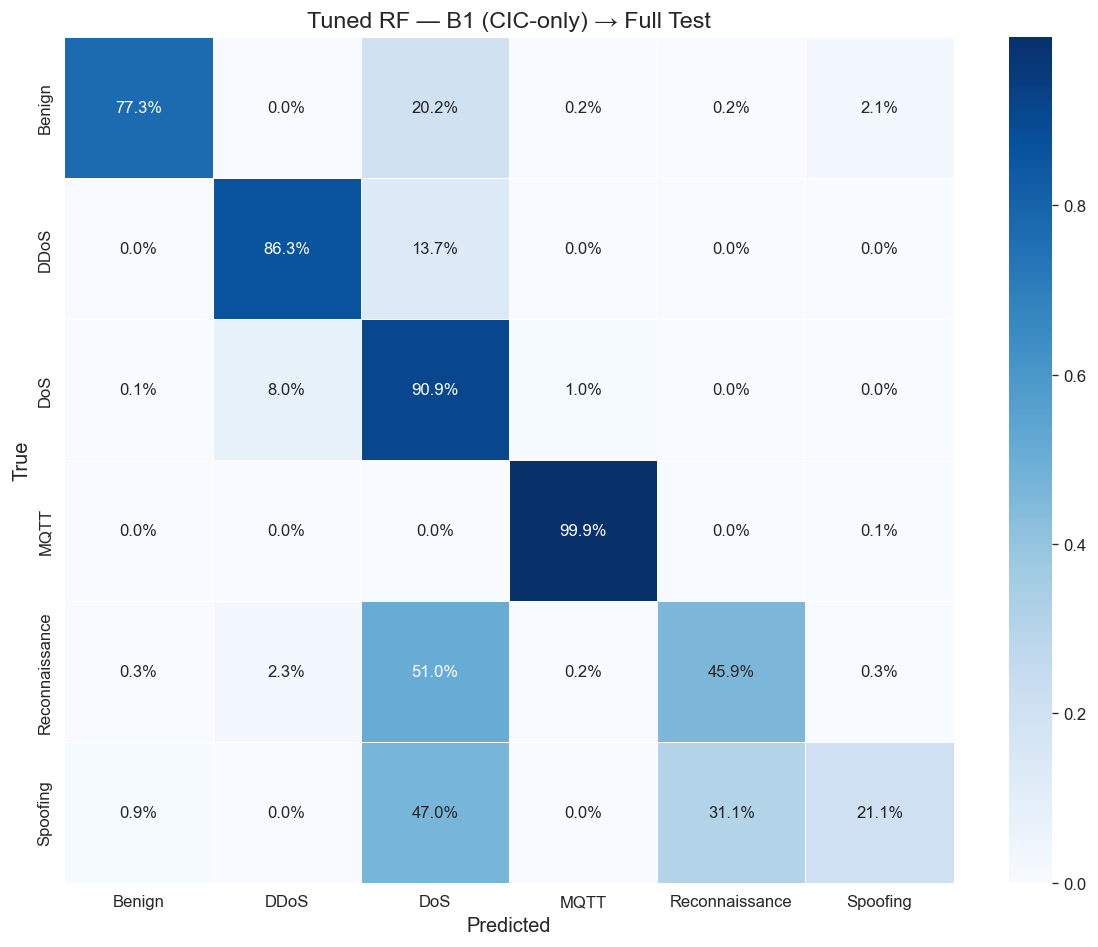

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_cm_b2_full.png


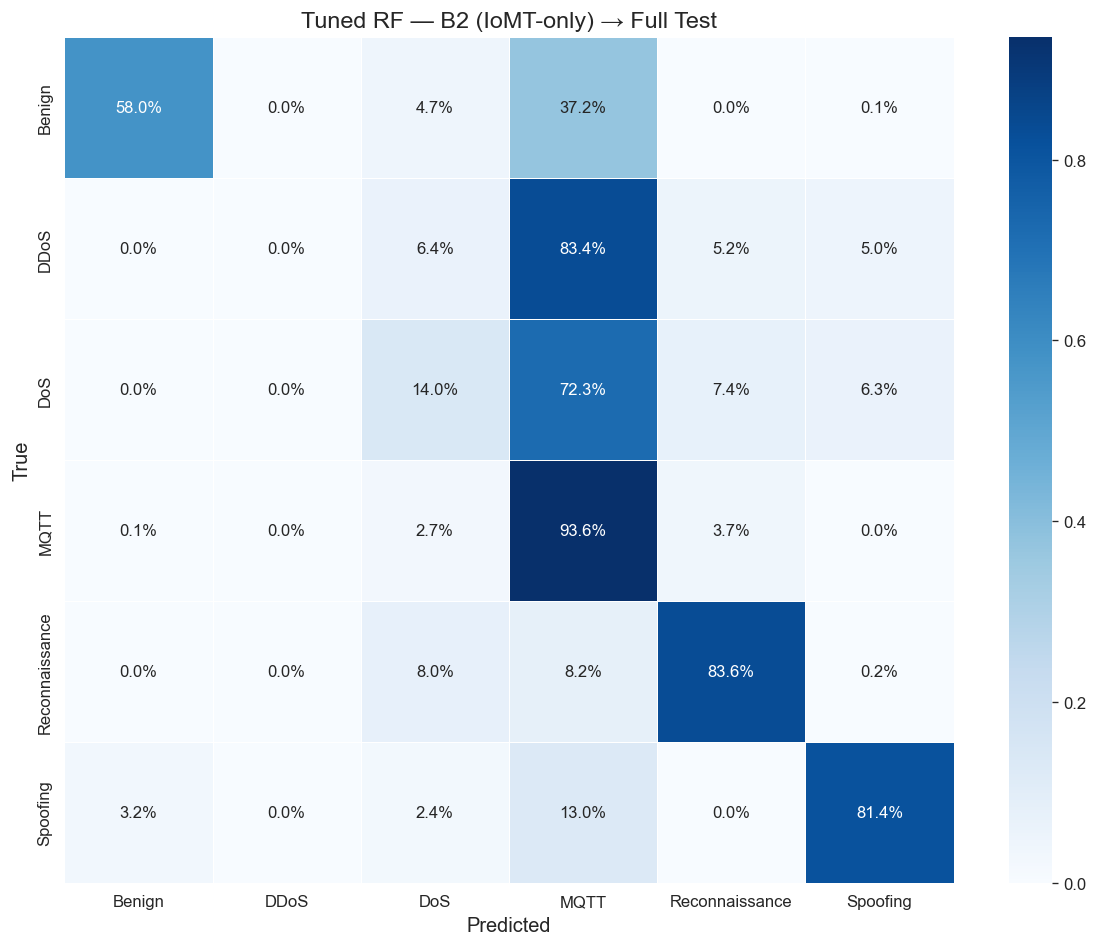

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_cm_u_full.png


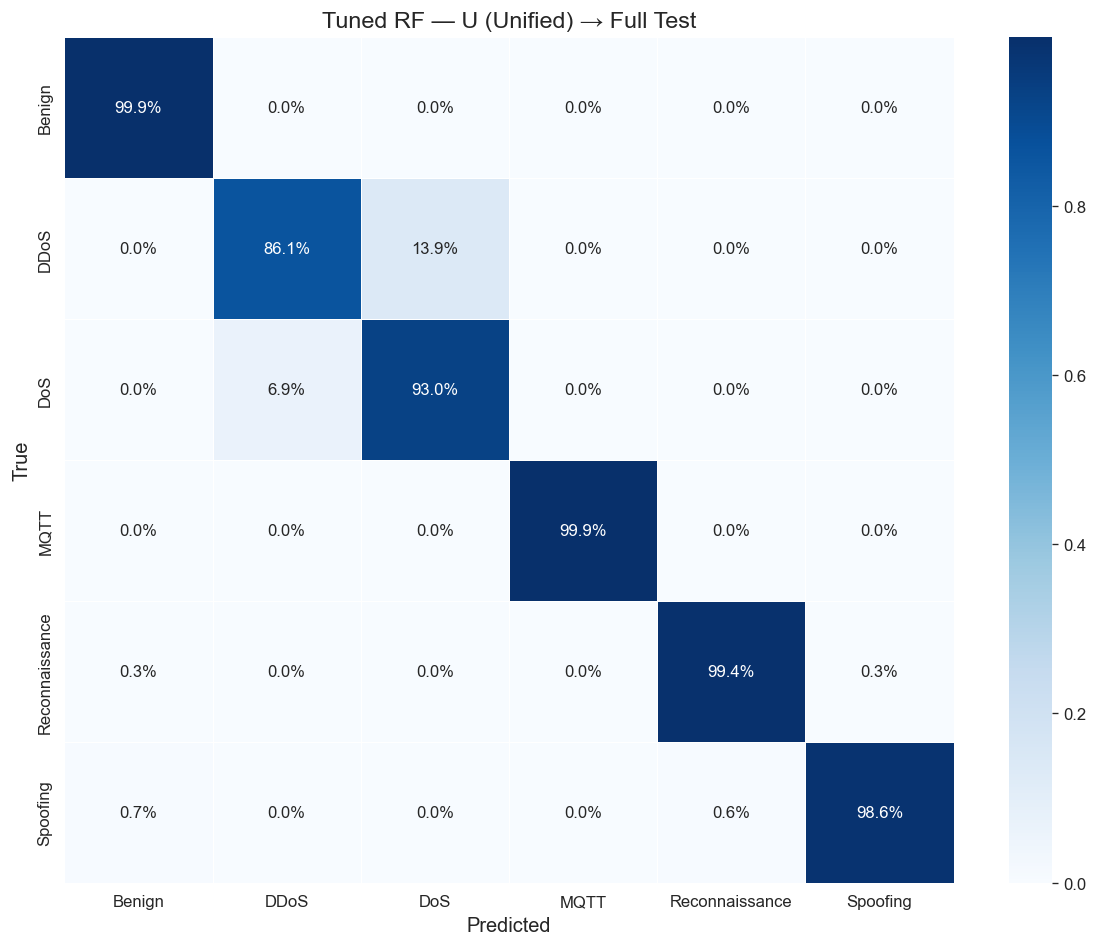

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_cm_b1_xd_iomt.png


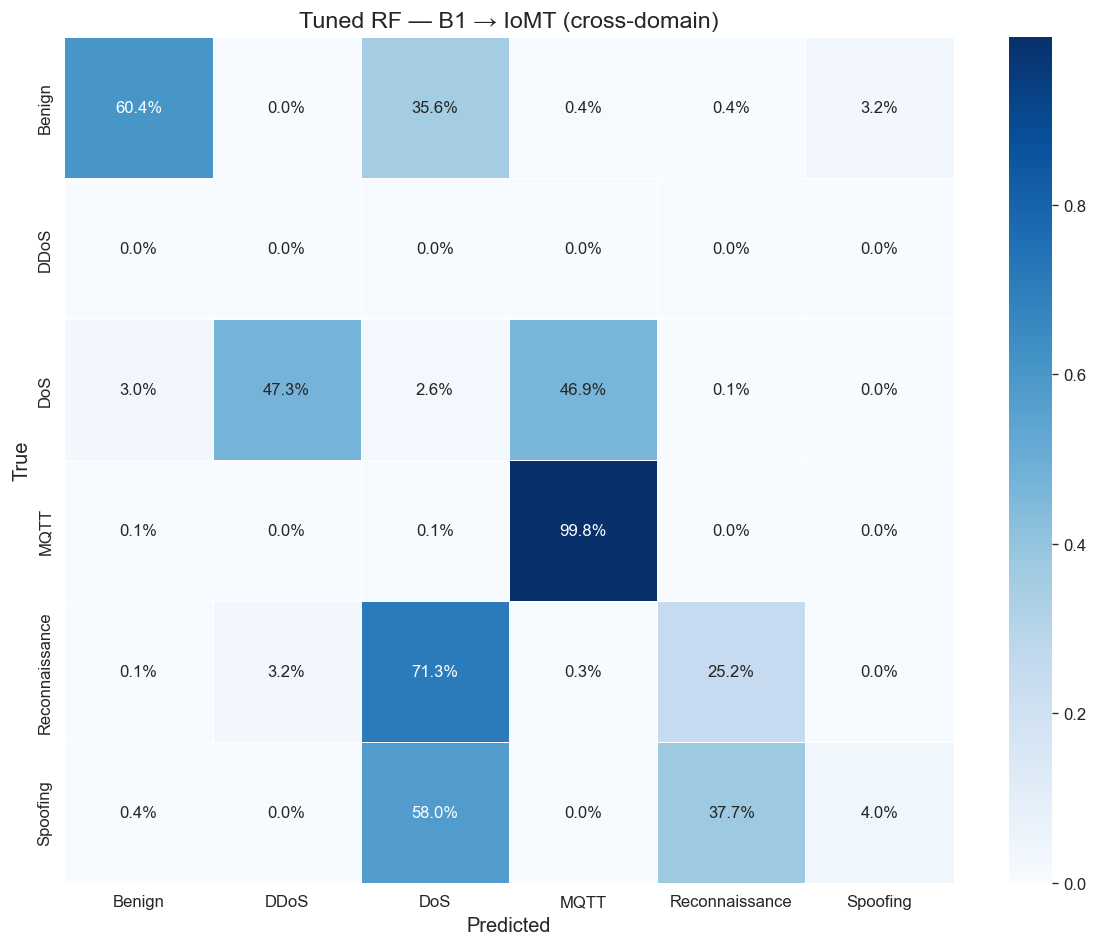

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_cm_b2_xd_cic.png


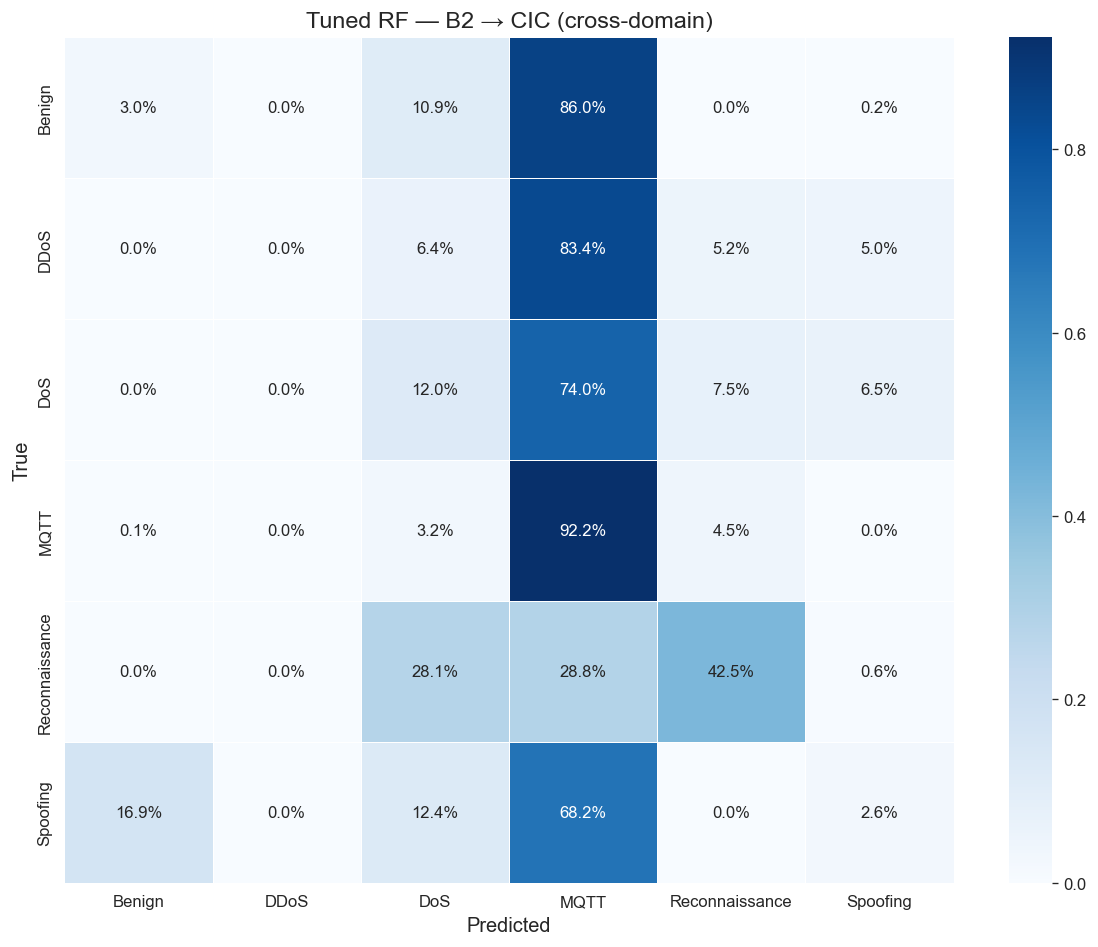

In [14]:
# --- Confusion Matrices (Tuned models, full test set) ---
for regime_key in ("B1", "B2", "U"):
    res_key = f"Tuned-{regime_key}"
    cm = tuned_xd_results[res_key]["full"]["cm"]
    fig = plot_confusion_matrix(
        cm, GLOBAL_CLASSES,
        title=f"Tuned RF — {regime_key} ({REGIME_LABEL[regime_key]}) → Full Test",
        save_path=str(FIGURES_DIR / f"ch5_rf_cm_{regime_key.lower()}_full.png"),
    )
    plt.show()
    plt.close(fig)

# Cross-domain confusion matrices
xd_pairs = [("B1", "IoMT-TrafficData", "IoMT"),
            ("B2", "CICIoMT2024", "CIC")]
for regime_key, other_src, tag in xd_pairs:
    res_key = f"Tuned-{regime_key}"
    if other_src in tuned_xd_results[res_key]:
        cm = tuned_xd_results[res_key][other_src]["cm"]
        fig = plot_confusion_matrix(
            cm, GLOBAL_CLASSES,
            title=f"Tuned RF — {regime_key} → {tag} (cross-domain)",
            save_path=str(FIGURES_DIR / f"ch5_rf_cm_{regime_key.lower()}_xd_{tag.lower()}.png"),
        )
        plt.show()
        plt.close(fig)

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_feature_importance_unified.png


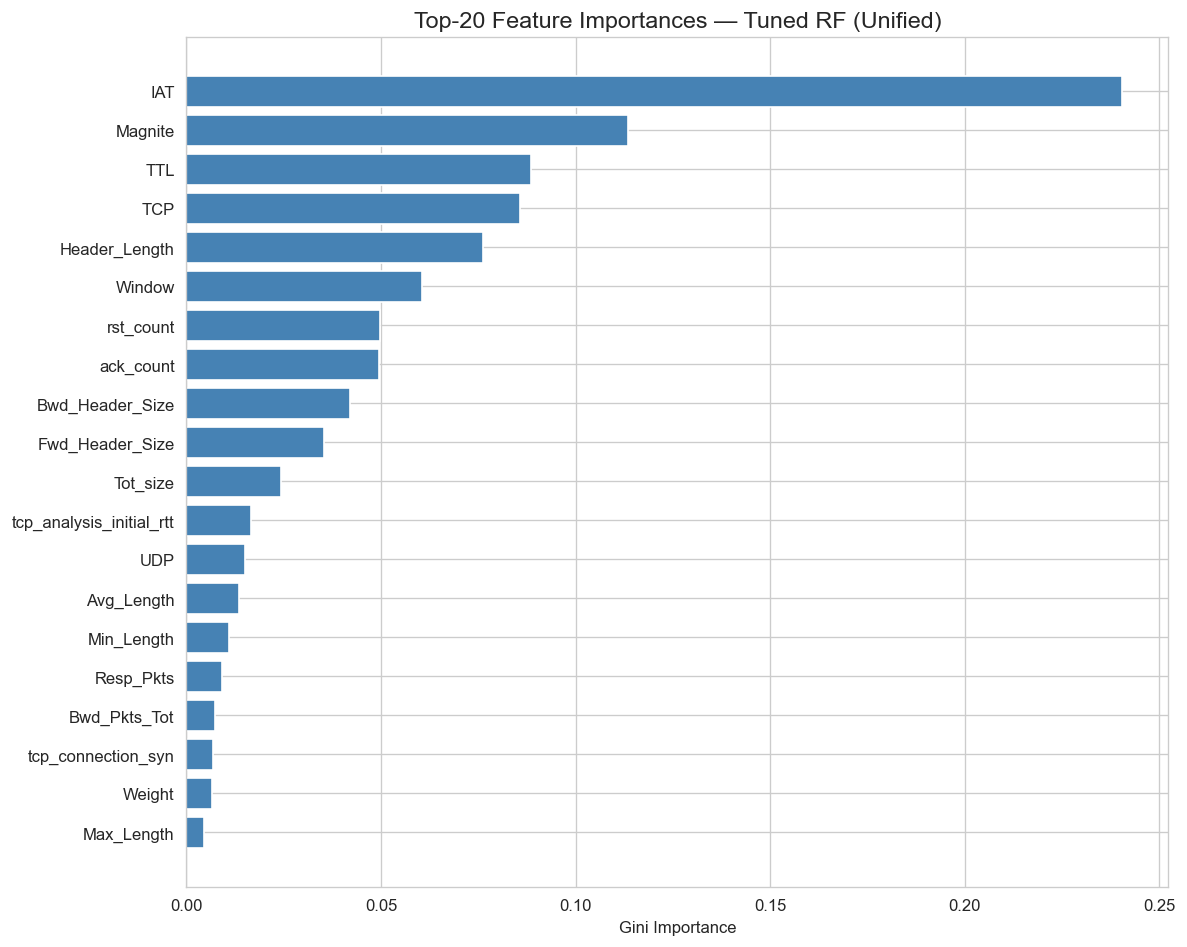

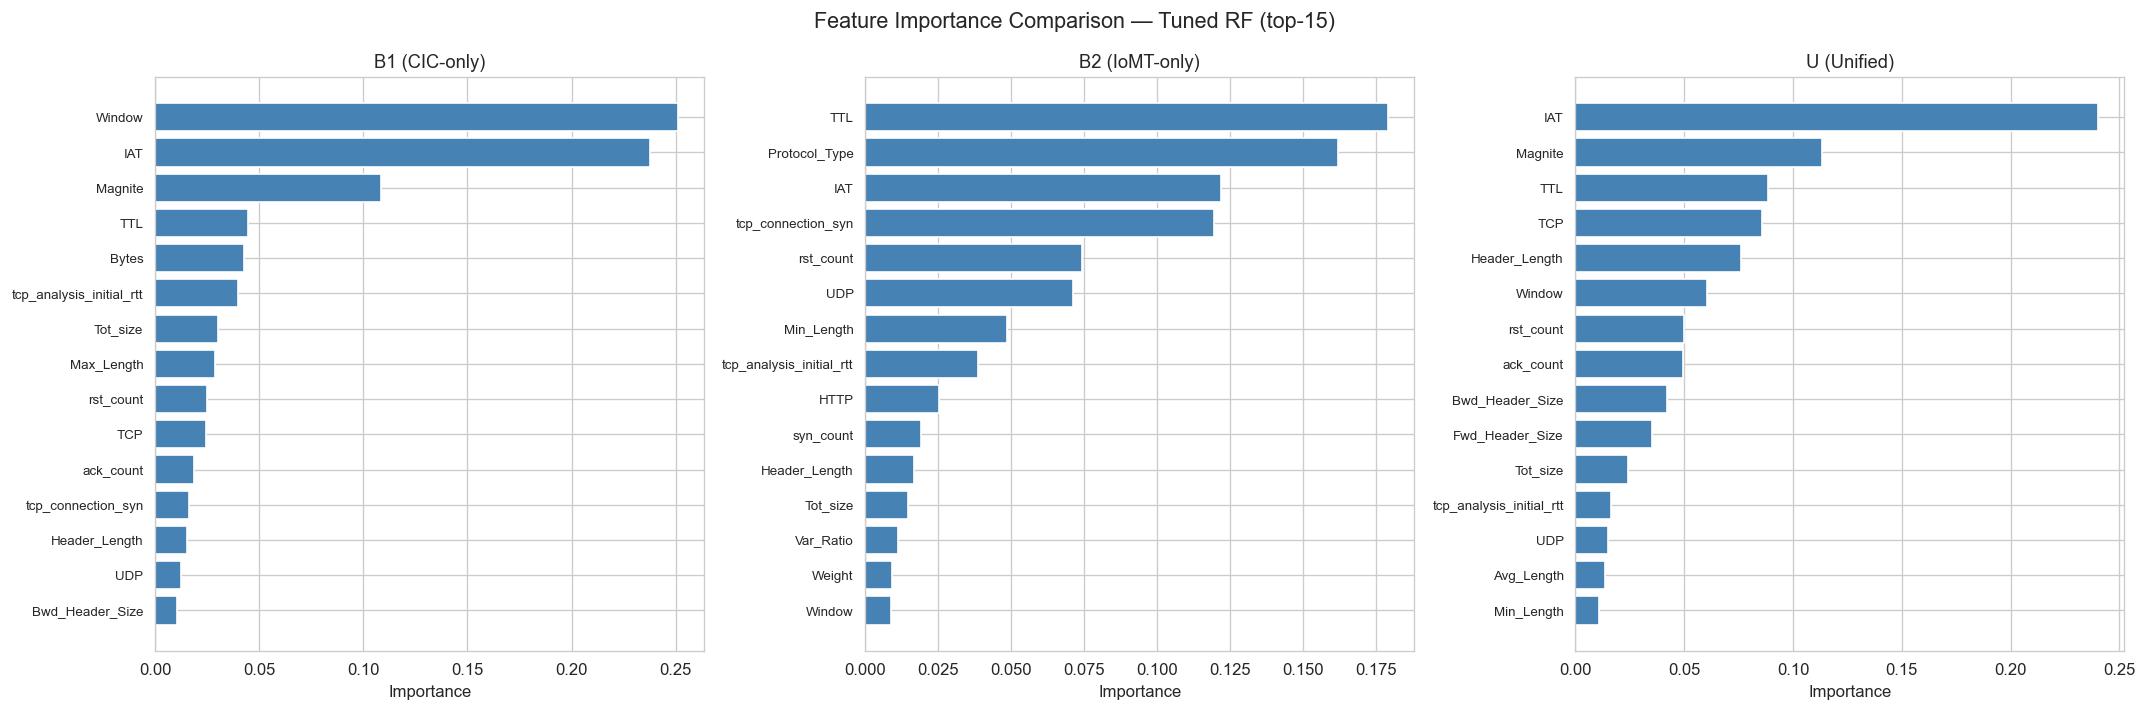

In [15]:
# --- Feature importance (Unified tuned RF) ---
fig = plot_feature_importance(
    tuned_models["U"], feature_cols, top_n=20,
    title="Top-20 Feature Importances — Tuned RF (Unified)",
    save_path=str(FIGURES_DIR / "ch5_rf_feature_importance_unified.png"),
)
plt.show()
plt.close(fig)

# --- Feature importance comparison (3 regimes) ---
top_n = 15
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)
for ax, regime_key in zip(axes, ("B1", "B2", "U")):
    imp = tuned_models[regime_key].feature_importances_
    idx = np.argsort(imp)[::-1][:top_n]
    y_pos = np.arange(top_n)
    ax.barh(y_pos, imp[idx[::-1]], color="steelblue")
    ax.set_yticks(y_pos)
    ax.set_yticklabels([feature_cols[i] for i in idx[::-1]], fontsize=8)
    ax.set_title(f"{regime_key} ({REGIME_LABEL[regime_key]})", fontsize=11)
    ax.set_xlabel("Importance")
fig.suptitle("Feature Importance Comparison — Tuned RF (top-15)", fontsize=13)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "ch5_rf_feature_importance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_regime_comparison.png


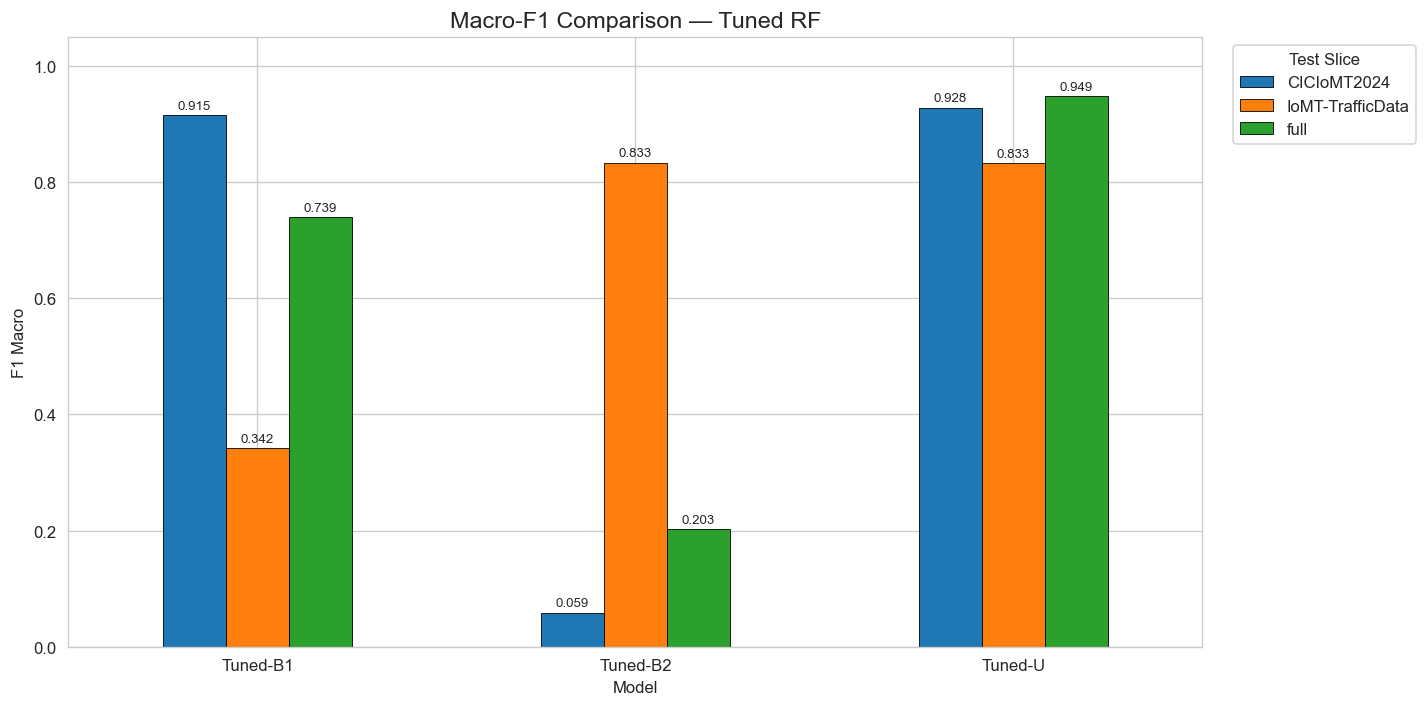

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_rf_per_class_f1.png


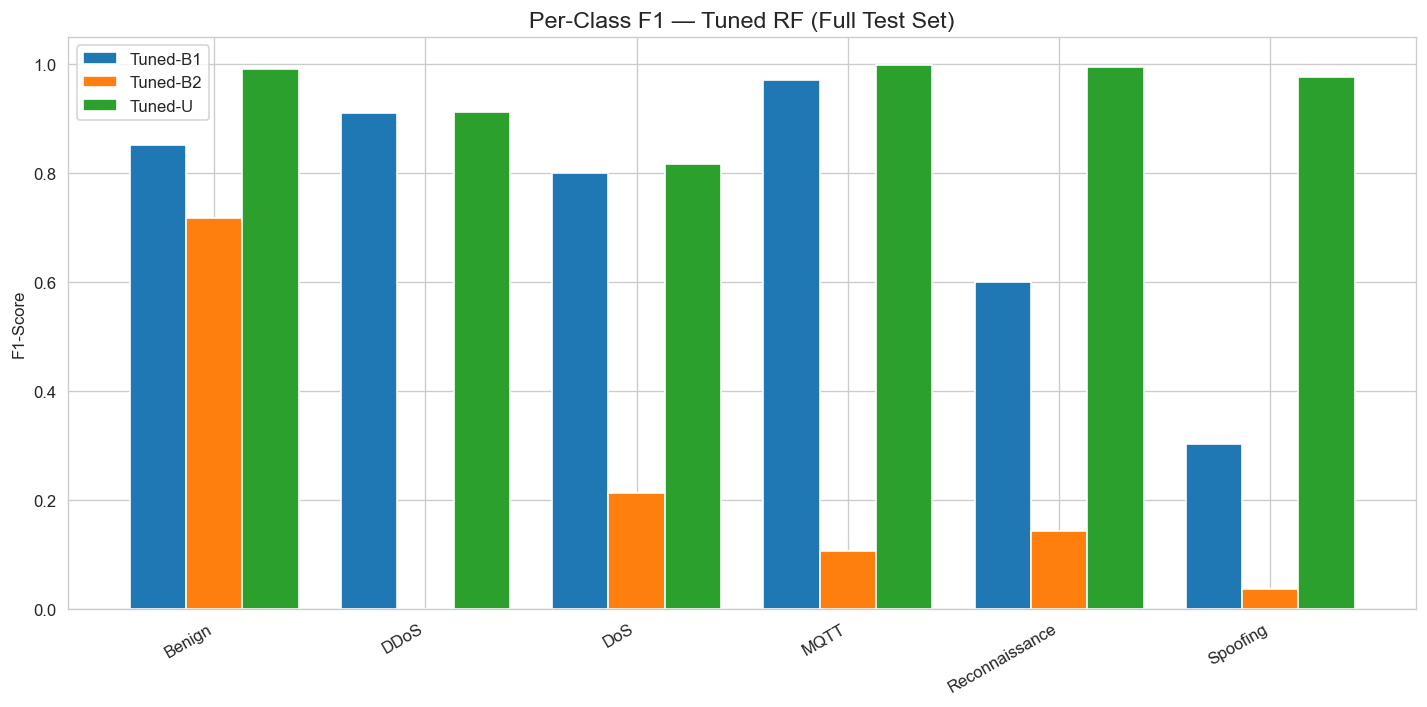

In [16]:
# --- Regime comparison (macro-F1) ---
fig = plot_regime_comparison(
    tuned_eval_df, metric="f1_macro",
    title="Macro-F1 Comparison — Tuned RF",
    save_path=str(FIGURES_DIR / "ch5_rf_regime_comparison.png"),
)
plt.show()
plt.close(fig)

# --- Per-class F1 ---
fig = plot_per_class_f1(
    tuned_xd_results, le, test_slice="full",
    title="Per-Class F1 — Tuned RF (Full Test Set)",
    save_path=str(FIGURES_DIR / "ch5_rf_per_class_f1.png"),
)
plt.show()
plt.close(fig)

## 9. Per-Class Analysis

In [17]:
from sklearn.metrics import classification_report as cr_text

for regime_key in ("B1", "B2", "U"):
    res_key = f"Tuned-{regime_key}"
    y_true = le.transform(splits["test"]["label_category"])
    y_pred = tuned_xd_results[res_key]["full"]["y_pred"]
    print("=" * 60)
    print(f"Classification Report — Tuned RF {regime_key} ({REGIME_LABEL[regime_key]}) → Full Test")
    print("=" * 60)
    print(cr_text(y_true, y_pred, target_names=GLOBAL_CLASSES, zero_division=0, digits=2))
    print()

Classification Report — Tuned RF B1 (CIC-only) → Full Test
                precision    recall  f1-score   support

        Benign       0.95      0.77      0.85      8018
          DDoS       0.96      0.86      0.91    805244
           DoS       0.72      0.91      0.80    322273
          MQTT       0.94      1.00      0.97     57891
Reconnaissance       0.87      0.46      0.60      6904
      Spoofing       0.54      0.21      0.30      1401

      accuracy                           0.88   1201731
     macro avg       0.83      0.70      0.74   1201731
  weighted avg       0.90      0.88      0.88   1201731




Classification Report — Tuned RF B2 (IoMT-only) → Full Test
                precision    recall  f1-score   support

        Benign       0.94      0.58      0.72      8018
          DDoS       0.00      0.00      0.00    805244
           DoS       0.45      0.14      0.21    322273
          MQTT       0.06      0.94      0.11     57891
Reconnaissance       0.08      0.84      0.14      6904
      Spoofing       0.02      0.81      0.04      1401

      accuracy                           0.09   1201731
     macro avg       0.26      0.55      0.20   1201731
  weighted avg       0.13      0.09      0.07   1201731




Classification Report — Tuned RF U (Unified) → Full Test
                precision    recall  f1-score   support

        Benign       0.98      1.00      0.99      8018
          DDoS       0.97      0.86      0.91    805244
           DoS       0.73      0.93      0.82    322273
          MQTT       1.00      1.00      1.00     57891
Reconnaissance       1.00      0.99      1.00      6904
      Spoofing       0.97      0.99      0.98      1401

      accuracy                           0.89   1201731
     macro avg       0.94      0.96      0.95   1201731
  weighted avg       0.91      0.89      0.89   1201731




In [18]:
from IPython.display import display, Markdown

b1_full = tuned_xd_results["Tuned-B1"]["full"]["metrics"]["f1_macro"]
b2_full = tuned_xd_results["Tuned-B2"]["full"]["metrics"]["f1_macro"]
u_full  = tuned_xd_results["Tuned-U"]["full"]["metrics"]["f1_macro"]
b1_xd   = tuned_xd_results["Tuned-B1"].get("IoMT-TrafficData", {}).get("metrics", {}).get("f1_macro", 0)
b2_xd   = tuned_xd_results["Tuned-B2"].get("CICIoMT2024", {}).get("metrics", {}).get("f1_macro", 0)
u_cic   = tuned_xd_results["Tuned-U"].get("CICIoMT2024", {}).get("metrics", {}).get("f1_macro", 0)
u_iomt  = tuned_xd_results["Tuned-U"].get("IoMT-TrafficData", {}).get("metrics", {}).get("f1_macro", 0)

summary_md = f"""## 10. Summary — Random Forest

| Metric | B1 (CIC-only) | B2 (IoMT-only) | U (Unified) |
|--------|--------------|----------------|-------------|
| **Full test macro-F1** | {b1_full:.4f} | {b2_full:.4f} | **{u_full:.4f}** |
| Cross-domain macro-F1 | {b1_xd:.4f} (→IoMT) | {b2_xd:.4f} (→CIC) | CIC={u_cic:.4f} / IoMT={u_iomt:.4f} |

**Key findings:**
- Unified RF achieves macro-F1 = {u_full:.4f} on the full test set.
- Absolute improvement over best single-source: +{(u_full - max(b1_full, b2_full))*100:.1f} pp.
- Single-source models still fail cross-domain (B1→IoMT: {b1_xd:.4f}, B2→CIC: {b2_xd:.4f}).

Next: XGBoost experiments (notebook 10).
"""
display(Markdown(summary_md))

## 10. Summary — Random Forest

| Metric | B1 (CIC-only) | B2 (IoMT-only) | U (Unified) |
|--------|--------------|----------------|-------------|
| **Full test macro-F1** | 0.7395 | 0.2029 | **0.9487** |
| Cross-domain macro-F1 | 0.3423 (→IoMT) | 0.0586 (→CIC) | CIC=0.9285 / IoMT=0.8329 |

**Key findings:**
- Unified RF achieves macro-F1 = 0.9487 on the full test set.
- Absolute improvement over best single-source: +20.9 pp.
- Single-source models still fail cross-domain (B1→IoMT: 0.3423, B2→CIC: 0.0586).

Next: XGBoost experiments (notebook 10).
